# 02 - Studio di Sensibilità ai Carichi Prandiali Non Annunciati (adult#001: 30, 60, 90 g)

In questo notebook viene condotto il **confronto sistematico tra il PID standard e il controllore vincolato (PID + IOB + PLGS)** al variare dell'entità del disturbo prandiale non annunciato, mantenendo fisso il paziente di riferimento (`adult#001`).

### Carichi analizzati:
- **30 g CHO**: spuntino o pasto leggero;
- **60 g CHO**: pasto standard nominale di riferimento;
- **90 g CHO**: pasto abbondante ad alto carico glucidico.

Tutte le simulazioni hanno durata di **16 ore** (dalle 08:00 alle 24:00, 320 passi da 3 minuti) con pasto somministrato alle ore 12:00 (`t = 4.0 h`).

## 1. Ambiente software e versioni delle librerie

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import aid_sim as A
import notebook_utils as nu
pd.set_option('display.width', 200)

# Documentazione versioni librerie
display(nu.library_versions())

/Users/marti/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


,Pacchetto,Versione
0,Python,3.9.6
1,simglucose,0.2.11
2,numpy,2.0.2
3,scipy,1.13.1
4,pandas,2.3.3
5,matplotlib,3.9.4


## 2. Specifiche del controllore e condizioni dello scenario

In [2]:
ic = nu.initial_conditions('adult#001', seed=1)

# Tabella parametri, vincoli e unita' di misura
display(nu.controller_table(ctrl_kwargs={'use_iob': True, 'use_plgs': True}, basal_u_per_min=ic['ub']))

# Tabella protocollo di simulazione
display(nu.scenario_table('adult#001', cho=60.0, seed=1))

,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.000005,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM (segno ...
4,i_min,-2000.0,mg*min/dL,Limite inferiore anti-windup (clamping)
5,i_max,10000.0,mg*min/dL,Limite superiore anti-windup (clamping)
6,use_iob,True,-,Attiva il vincolo dinamico sull'insulina attiv...
7,iob_alpha,1.5,adimensionale,Fattore di scala: tetto IOB = iob_alpha * basa...
8,tau_s,50.0,min,Costante di tempo dei compartimenti sottocutan...
9,use_plgs,True,-,Attiva la sospensione predittiva dell'infusion...


,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore autoregressivo UVA/Padova),-
5,Pompa di infusione,Insulet,-
6,Seme casuale sensore (seed),1,-
7,Inizio simulazione,08:00,ora solare
8,Durata simulazione,16.0,h
9,Passo di campionamento dt,3.0,min


## 3. Simulazione sistematica sui carichi (30 g, 60 g, 90 g)

In [3]:
cho_levels = [30.0, 60.0, 90.0]
sim_results = {}
metric_rows = []

for cho in cho_levels:
    df_pid, ub = A.simulate('adult#001', cho, {})
    df_prop, _ = A.simulate('adult#001', cho, dict(use_iob=True, use_plgs=True))
    sim_results[cho] = (df_pid, df_prop, ub)
    
    for df, name in [(df_pid, 'PID'), (df_prop, 'PID+IOB+PLGS')]:
        m = A.metrics(df)
        m['TBR_tardivo'] = 100 * np.mean(df[df.t_h >= A.MEAL_OFFSET_H + 3].BG.values < 70)
        metric_rows.append({
            'CHO [g]': int(cho),
            'Controllore': name,
            **{k: round(float(v), 1) for k, v in m.items()}
        })

df_metrics = pd.DataFrame(metric_rows)
display(df_metrics[['CHO [g]', 'Controllore', 'TIR', 'TAR', 'TBR', 'TBR<54', 'TBR_tardivo', 'picco', 'nadir']])

,CHO [g],Controllore,TIR,TAR,TBR,TBR<54,TBR_tardivo,picco,nadir
0,30,PID,68.8,0.0,31.2,23.1,55.6,154.8,44.1
1,30,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,154.8,76.8
2,60,PID,60.6,7.5,31.9,26.6,56.7,186.3,30.4
3,60,PID+IOB+PLGS,92.2,7.8,0.0,0.0,0.0,186.3,73.1
4,90,PID,45.0,24.4,30.6,26.2,54.4,218.1,25.8
5,90,PID+IOB+PLGS,70.9,29.1,0.0,0.0,0.0,218.2,74.8


## 4. Confronto grafico della dinamica glicemica

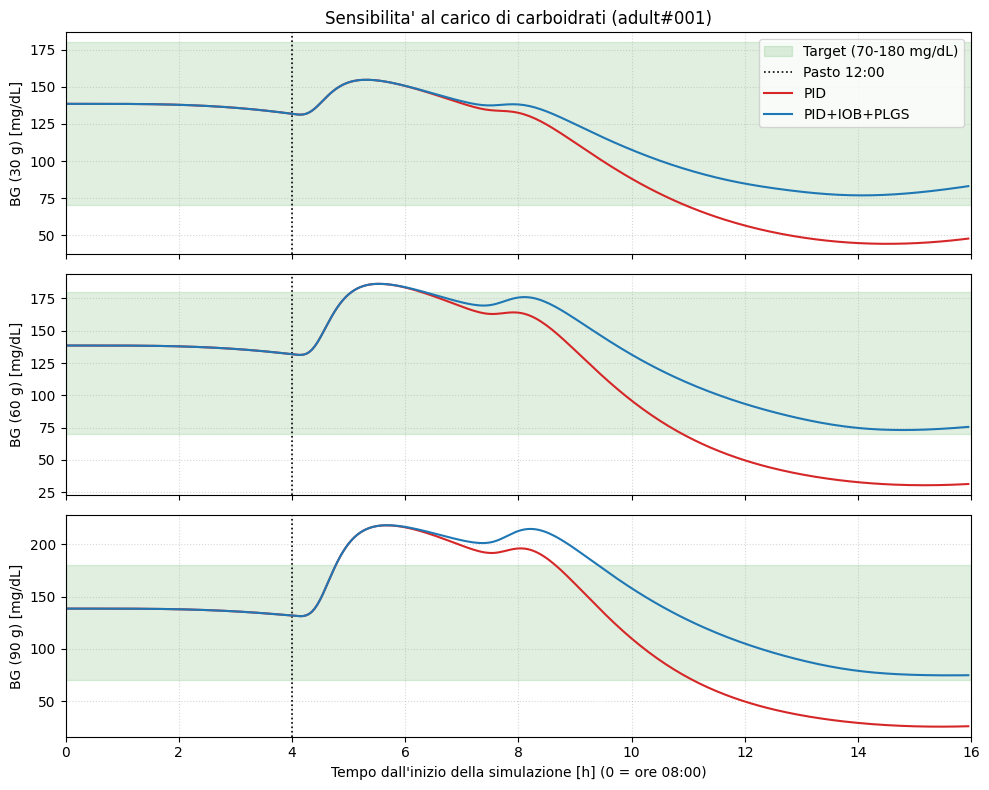

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for idx, cho in enumerate(cho_levels):
    ax = axes[idx]
    df_p, df_i, _ = sim_results[cho]
    
    ax.axhspan(70, 180, color='green', alpha=0.12, label='Target (70-180 mg/dL)' if idx == 0 else '')
    ax.axvline(A.MEAL_OFFSET_H, color='k', ls=':', lw=1.2, label='Pasto 12:00' if idx == 0 else '')
    ax.plot(df_p.t_h, df_p.BG, color='tab:red', label='PID')
    ax.plot(df_i.t_h, df_i.BG, color='tab:blue', label='PID+IOB+PLGS')
    
    ax.set_ylabel(f'BG ({int(cho)} g) [mg/dL]')
    ax.grid(ls=':', alpha=0.5)
    if idx == 0:
        ax.set_title('Sensibilita\' al carico di carboidrati (adult#001)')
        ax.legend(loc='upper right')

axes[2].set_xlabel('Tempo dall\'inizio della simulazione [h] (0 = ore 08:00)')
axes[2].set_xlim(0, 16)
plt.tight_layout()
plt.show()

## 5. Conclusioni e discussione clinica
1. **TIR e controllo glicemico**: A 30 g il controllore proposto raggiunge un TIR del 100% (contro il 68.8% del PID). A 60 g e 90 g il TIR è pari rispettivamente al 92.2% e al 70.9%.
2. **Azzeramento dell'ipoglicemia tardiva**: Per tutti e tre i carichi il controllore proposto registra **TBR = 0.0%** e **TBR tardivo = 0.0%**, mentre il PID nominale va in ipoglicemia severa per effetto dell'accumulo di insulina (TBR tardivo ~55%).
3. **Invarianza del picco postprandiale**: Il picco massimo rimane pressoché invariato tra i due controllori (186.3 mg/dL a 60 g e 218.2 mg/dL a 90 g), a dimostrazione che il vincolo IOB preserva la sicurezza senza degradare la reiezione dell'iperglicemia iniziale.